# Analyse R-SIM Dataset, Preprocess & Negative Sampling #

In [78]:
import os
import sys
sys.path.append("/home/gavrilev/Thesis/src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
ALL_SFM_DATA = '/home/gavrilev/Thesis/src/datasets/RSIM/All_sf_dataset_v1.csv'

COLD_PATH = '/home/gavrilev/Thesis/src/datasets/blind_test/'
COLD_PATH_RNA_SAVE = '/home/gavrilev/Thesis/src/datasets/blind_test/rna/train_test_splits/'

In [3]:
all_sfm_df = pd.read_csv(ALL_SFM_DATA, delimiter='\t')
all_sfm_df

,Entry_ID,SMILES,Target_RNA_sequence,Molecule_name,Molecule_ID,Target_RNA_name,Target_RNA_ID,pKd
0,2091,N[C@@H]1C[C@H](N)[C@H]([C@H]([C@H]1OCCCc1nnn(c...,CGCGCAGUCAGUAGCGCG,B-13,Target_lig_1138,RNA hairpin loop IV,Target_381,6.387216
1,162,C1CN(CCC1C(=O)NCCN2CCOCC2)CC3=CC=C(C=C3)Cl,GAGCGUCACACCUUCGGGUGAAGUCGCUC,1-(4-chlorobenzyl)-N-(2-morpholinoethyl)piperi...,Target_lig_132,A-site 16S rRNA_E_coli (1),Target_3,3.602060
2,270,c1c(ccc2Sc3ccccc3N(c12)CCCNCN(CO)CO)C(=O)C,GGCAGAUCUGAGCCUGGGAGCUCUCUGCC,3_phenothiazine_analog_1,Target_lig_210,HIV-1 TAR RNA,Target_19,2.522879
3,1327,C(CN1C=C(CNC2=C3C=CC=CC3=[NH+]C3=C2OC2=C3C=CC=...,GGGUUAGGGU,Quindoline CK1-14,Target_lig_723,TRF2:TERRA G-quadruplex (TERRA22):Telomeric du...,Target_262,6.272784
4,1907,C1=CC=C(C=C1)C2=NN=C(O2)C3=NC4=CC=CC=C4C(=N3)N...,UGUGGGAGGGGCGGGUCUGGG,NRAS SAR 7,Target_lig_1057,NRAS G4 motif,Target_259,6.443697
...,...,...,...,...,...,...,...,...
1434,2119,CN(C)C1=CC2=C(C=C1)C(=C3C=CC(=[N+](C)C)C=C3O2)...,GGUACCCGUCUGGCGAGAGCCAGGUAACGAAUGGUACC,Tetramethylrosamine (TMR),Target_lig_1151,Aptamer mutant U9,Target_388,6.853872
1435,1248,C1=CC(=CC=C1C2=CC=C(O2)C3=CC=C(C=C3)C(=[NH2+])...,GGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCA...,DB75,Target_lig_697,"HTT exon1 RNA, 18 repeats",Target_215,4.222573
1436,1336,OC(Cn1c2ccc(cc2c2c1ccc(c2)Br)Br)CNc1ccc(cc1)N1...,GGGUUGACUGUUGAAUCUCAUGGCAACCC,Aniline_analog_7,Target_lig_731,miR-21 hairpin,Target_265,5.677781
1437,1810,NCCCC(=O)NCCCN1Cc2ccc3c(n2)nc(cc3)NC(=O)OCC/C=...,GCUGAUUUCUUUUGGUGUUCAGAGUGGUCGGUGGUUGGUGGUGGGU...,CMBL-3aL,Target_lig_1018,R-Seq2,Target_322,5.882729


<function matplotlib.pyplot.show(close=None, block=None)>

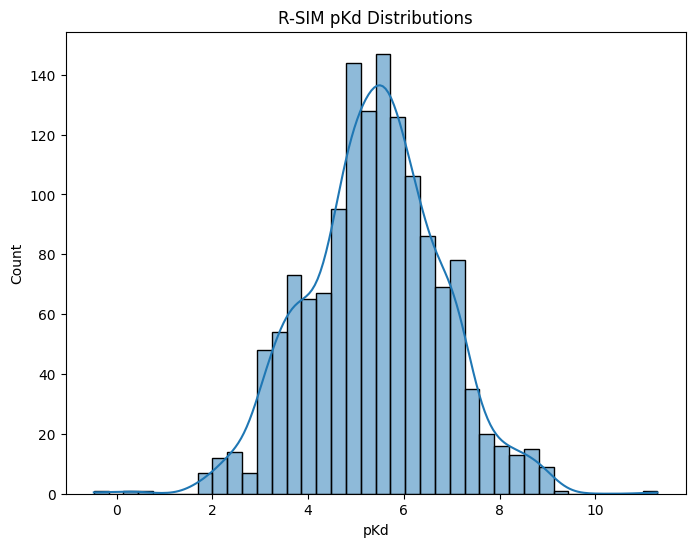

In [85]:
plt.figure(figsize=(8,6))
sns.histplot(data=all_sfm_df, x="pKd", kde=True)
plt.title('R-SIM pKd Distributions')
plt.show

## Blind Test - Cold RNA ##

In [5]:
def load_cold_data(cold_type="cold_rna"):
    _ ,cold = cold_type.split('_')
    df1 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'1.csv', delimiter=',')
    df2 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'2.csv', delimiter=',')
    df3 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'3.csv', delimiter=',')
    df4 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'4.csv', delimiter=',')
    df5 = pd.read_csv(COLD_PATH + cold + '/' + cold_type +'5.csv', delimiter=',')
    cold_dfs = [df1, df2, df3, df4, df5]
    return cold_dfs

def get_cold_splits(curr_cold_df=None, cold_dfs=None, all_df=None, fold=0):
    """
    Generate train/test indices for a given cold-start fold.

    Args:
        curr_cold_df (pd.DataFrame): current fold dataframe used as test set.
        cold_dfs (list[pd.DataFrame]): list of all cold split dataframes.
        all_df (pd.DataFrame): full dataset containing Entry_ID column.
        fold (int): index of the current test fold.

    Returns:
        tuple[list[int], list[int]]: train indices, test indices.
    """
    if curr_cold_df is None or cold_dfs is None or all_df is None:
        raise ValueError("Either curr_cold_df/cold_dfs/all_df is None")

    test_id = curr_cold_df['Entry_ID'].tolist()
    test_id = all_df[all_df['Entry_ID'].isin(test_id)].index.tolist()

    train_id = []
    for j, other_df in enumerate(cold_dfs):
        if j != fold:
            train_id.extend(other_df['Entry_ID'].tolist())

    train_id = all_df[all_df['Entry_ID'].isin(train_id)].index.tolist()
    return train_id, test_id

In [6]:
cold_rna_dfs = load_cold_data(cold_type="cold_rna")
len(cold_rna_dfs)

5

In [7]:
all_sfm_df.columns

Index(['Entry_ID', 'SMILES', 'Target_RNA_sequence', 'Molecule_name',
       'Molecule_ID', 'Target_RNA_name', 'Target_RNA_ID', 'pKd'],
      dtype='object')

In [8]:
# senaty check that verifies that DeepRSMA cold start setting is valid
for i in range(5):
    for j in range(i + 1, 5):
        overlap = set(cold_rna_dfs[i]['Entry_ID']) & set(cold_rna_dfs[j]['Entry_ID'])
        print(f"fold {i+1} vs fold {j+1}: {len(overlap)}")

fold 1 vs fold 2: 0
fold 1 vs fold 3: 0
fold 1 vs fold 4: 0
fold 1 vs fold 5: 0
fold 2 vs fold 3: 0
fold 2 vs fold 4: 0
fold 2 vs fold 5: 0
fold 3 vs fold 4: 0
fold 3 vs fold 5: 0
fold 4 vs fold 5: 0


In [12]:
set(cold_rna_dfs[0]['Entry_ID']).intersection(cold_rna_dfs[1]['Entry_ID']) # senaty check

set()

In [13]:
cold_folds = []
for i in range(5):
    print('###################')
    train_id, test_id = get_cold_splits(curr_cold_df=cold_rna_dfs[i], cold_dfs=cold_rna_dfs, all_df=all_sfm_df, fold=i)
    curr_train_df = all_sfm_df.iloc[train_id, :]
    curr_test_df = all_sfm_df.iloc[test_id, :]
    print(f'Fold -> {i+1}, train -> {curr_train_df.shape[0]}, test -> {curr_test_df.shape[0]}')
    overlap = set(curr_train_df['Entry_ID']) & set(curr_test_df['Entry_ID'])
    assert len(overlap) == 0 # senaty check
    cold_folds.append((curr_train_df, curr_test_df))

###################
Fold -> 1, train -> 1256, test -> 183
###################
Fold -> 2, train -> 1196, test -> 243
###################
Fold -> 3, train -> 1134, test -> 305
###################
Fold -> 4, train -> 960, test -> 479
###################
Fold -> 5, train -> 1210, test -> 229


In [15]:
### save RNA cold start setting train/test splits
os.makedirs(COLD_PATH_RNA_SAVE, exist_ok=True)

for i, (train_df, test_df) in enumerate(cold_folds, 1):
    train_df.to_csv(os.path.join(COLD_PATH_RNA_SAVE, f"cold_rna_train_fold{i}.csv"), index=False)
    test_df.to_csv(os.path.join(COLD_PATH_RNA_SAVE, f"cold_rna_test_fold{i}.csv"), index=False)

### Blind RNA - pKd Distributions over 5 Training Folds ###

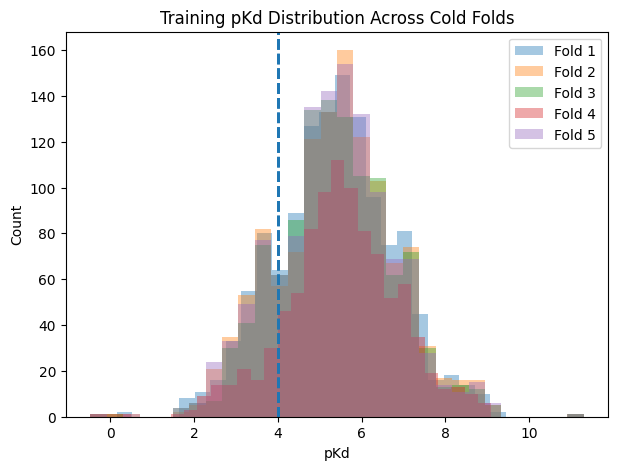

In [16]:
plt.figure(figsize=(7,5))

for i in range(5):
    plt.hist(
        cold_folds[i][0]['pKd'],
        bins=30,
        alpha=0.4,
        label=f'Fold {i+1}'
    )
    plt.axvline(4, linestyle='--', linewidth=2) 

plt.xlabel("pKd")
plt.ylabel("Count")
plt.title("Training pKd Distribution Across Cold Folds")
plt.legend()
plt.show()

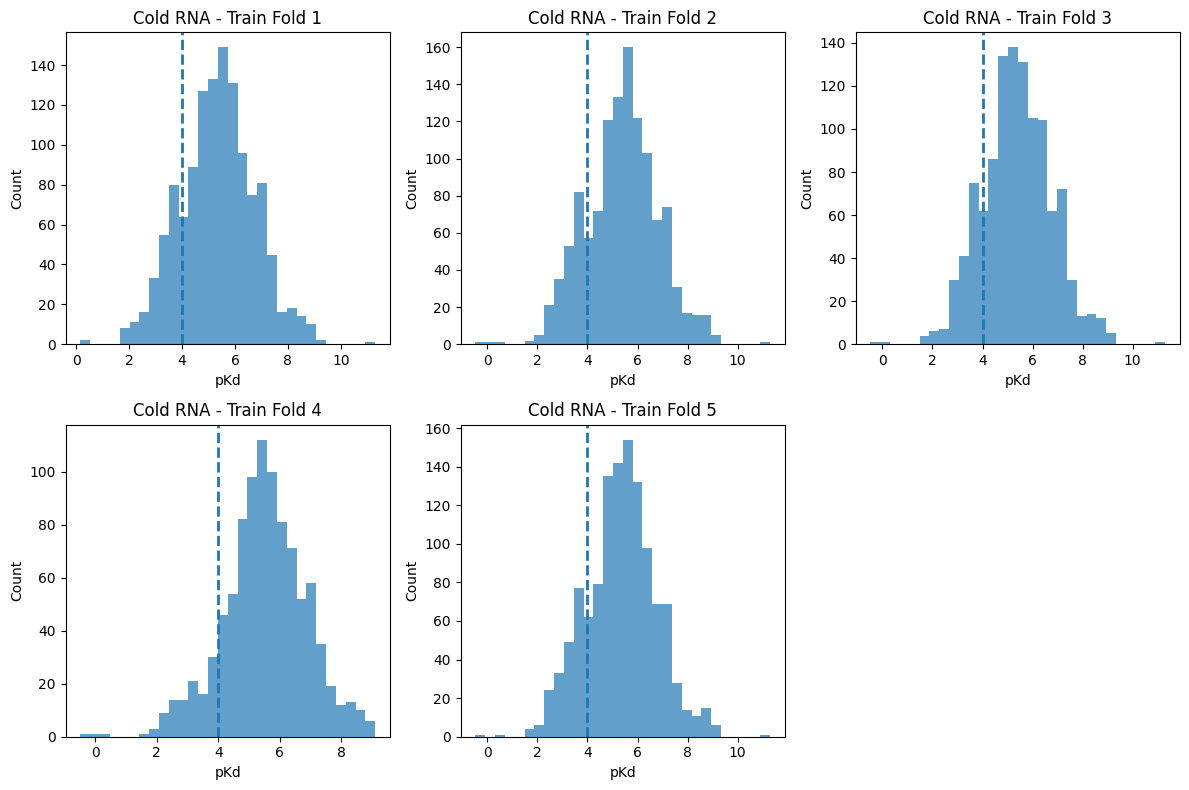

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for i in range(5):
    axes[i].hist(cold_folds[i][0]['pKd'], bins=30, alpha=0.7)
    axes[i].axvline(4, linestyle='--', linewidth=2)  
    axes[i].set_title(f"Cold RNA - Train Fold {i+1}")
    axes[i].set_xlabel("pKd")
    axes[i].set_ylabel("Count")

fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

## Negative Sampling with Smoothing Factor

To mitigate data scarcity and enrich the training data, we generate synthetic negative RNA–small molecule pairs using a smoothed frequency-based negative sampling strategy inspired by the PPIMI framework.

In this approach, we operate strictly within each training fold to avoid information leakage into validation or test sets. Positive samples are defined as RNA–ligand pairs with binding affinity pKd ≥ 4.0. For each positive interaction, we keep the ligand (SMILES) fixed and sample a new RNA target from the training fold according to a smoothed frequency distribution. The smoothing is implemented using power-law sampling, where the probability of sampling an RNA is proportional to its frequency raised to an exponent α (α = 0.75). This reduces the dominance of highly frequent RNAs while still preserving the natural data distribution.

To ensure valid synthetic negatives, sampled RNA–ligand pairs are rejected if the RNA is identical to the original RNA or if the resulting pair already exists in the training fold. Once a valid pair is obtained, a pseudo-binding affinity value is assigned to represent weak or non-binding interactions. These pseudo-pKd values are sampled from a continuous range below the binding threshold (pKd < 4.0). The lower bound of this range is determined using an interquartile range (IQR) rule to avoid extreme outliers, defined as:

Lower bound = Q1 − 1.5 × IQR

where Q1 and Q3 are the first and third quartiles of the real low-affinity samples in the training fold.

The generated synthetic negatives are then appended to the training fold and marked accordingly. This procedure increases the diversity of RNA–ligand combinations, maintains realistic affinity distributions, and improves model robustness under limited data conditions.

In [79]:
from utils.neg_smoo_aug import *

In [80]:
all_sfm_df = pd.read_csv(ALL_SFM_DATA, delimiter='\t')
all_sfm_df

,Entry_ID,SMILES,Target_RNA_sequence,Molecule_name,Molecule_ID,Target_RNA_name,Target_RNA_ID,pKd
0,2091,N[C@@H]1C[C@H](N)[C@H]([C@H]([C@H]1OCCCc1nnn(c...,CGCGCAGUCAGUAGCGCG,B-13,Target_lig_1138,RNA hairpin loop IV,Target_381,6.387216
1,162,C1CN(CCC1C(=O)NCCN2CCOCC2)CC3=CC=C(C=C3)Cl,GAGCGUCACACCUUCGGGUGAAGUCGCUC,1-(4-chlorobenzyl)-N-(2-morpholinoethyl)piperi...,Target_lig_132,A-site 16S rRNA_E_coli (1),Target_3,3.602060
2,270,c1c(ccc2Sc3ccccc3N(c12)CCCNCN(CO)CO)C(=O)C,GGCAGAUCUGAGCCUGGGAGCUCUCUGCC,3_phenothiazine_analog_1,Target_lig_210,HIV-1 TAR RNA,Target_19,2.522879
3,1327,C(CN1C=C(CNC2=C3C=CC=CC3=[NH+]C3=C2OC2=C3C=CC=...,GGGUUAGGGU,Quindoline CK1-14,Target_lig_723,TRF2:TERRA G-quadruplex (TERRA22):Telomeric du...,Target_262,6.272784
4,1907,C1=CC=C(C=C1)C2=NN=C(O2)C3=NC4=CC=CC=C4C(=N3)N...,UGUGGGAGGGGCGGGUCUGGG,NRAS SAR 7,Target_lig_1057,NRAS G4 motif,Target_259,6.443697
...,...,...,...,...,...,...,...,...
1434,2119,CN(C)C1=CC2=C(C=C1)C(=C3C=CC(=[N+](C)C)C=C3O2)...,GGUACCCGUCUGGCGAGAGCCAGGUAACGAAUGGUACC,Tetramethylrosamine (TMR),Target_lig_1151,Aptamer mutant U9,Target_388,6.853872
1435,1248,C1=CC(=CC=C1C2=CC=C(O2)C3=CC=C(C=C3)C(=[NH2+])...,GGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCAGCA...,DB75,Target_lig_697,"HTT exon1 RNA, 18 repeats",Target_215,4.222573
1436,1336,OC(Cn1c2ccc(cc2c2c1ccc(c2)Br)Br)CNc1ccc(cc1)N1...,GGGUUGACUGUUGAAUCUCAUGGCAACCC,Aniline_analog_7,Target_lig_731,miR-21 hairpin,Target_265,5.677781
1437,1810,NCCCC(=O)NCCCN1Cc2ccc3c(n2)nc(cc3)NC(=O)OCC/C=...,GCUGAUUUCUUUUGGUGUUCAGAGUGGUCGGUGGUUGGUGGUGGGU...,CMBL-3aL,Target_lig_1018,R-Seq2,Target_322,5.882729


In [81]:
# Molecule_name	Molecule_ID
len(all_sfm_df['Molecule_name'].unique()), len(all_sfm_df['Molecule_ID'].unique()), len(all_sfm_df['SMILES'].unique())

(808, 792, 759)

In [82]:
all_sfm_df.columns

Index(['Entry_ID', 'SMILES', 'Target_RNA_sequence', 'Molecule_name',
       'Molecule_ID', 'Target_RNA_name', 'Target_RNA_ID', 'pKd'],
      dtype='object')

In [83]:
len(all_sfm_df['Target_RNA_sequence'].unique()), len(all_sfm_df['Target_RNA_ID'].unique()), len(all_sfm_df['Target_RNA_name'].unique())

(295, 341, 397)

In [84]:
train_fold1_df = cold_folds[0][0]
train_fold1_df.shape

(1256, 8)

### Explore Negative Sampling Results ###

In [54]:
aug_train_df, synthetic_neg_df = generate_synthetic_negatives_for_train_fold(
    train_df=train_fold1_df,
    rna_col="Target_RNA_sequence",
    ligand_col="SMILES",
    pkd_col="pKd",
    threshold=4.0,
    alpha=0.75,
    negatives_per_positive=0.25,
    random_state=42,
)

In [58]:
aug_train_df.shape, synthetic_neg_df.shape

((1514, 12), (258, 12))

In [59]:
aug_train_df.shape, synthetic_neg_df.shape

((1514, 12), (258, 12))

In [56]:
train_fold1_df[train_fold1_df['pKd'] > 4.0].shape[0], aug_train_df[aug_train_df['pKd'] > 4.0].shape[0]

(1017, 1017)

In [57]:
train_fold1_df[train_fold1_df['pKd'] < 4.0].shape[0], aug_train_df[aug_train_df['pKd'] < 4.0].shape[0]

(223, 481)

In [47]:
synthetic_neg_df

,Entry_ID,SMILES,Target_RNA_sequence,Molecule_name,Molecule_ID,Target_RNA_name,Target_RNA_ID,pKd,is_synthetic_negative,binary_label
92,1564,CCCN(C(=O)CN(C(=O)CNCc1nnn(c1)CCCNC(=N)c1ccc(c...,CUCGGUACCGCAAAAGCGUUUUUCGCAUACCUAUUCGUUAUAGGUC...,2AU-2,Target_lig_1266,Spiegelmer L-A42d RNA (58 mer),Target_142,3.714398,1,0
799,1776,CN1CCN(CC1)c1cc(Nc2nccc(c2)Nc2ccc3c(n2)cccc3)n...,GGGAGAGGGUUUAAUUCGGCGGCGGCGGCGGCGGCGGCGGCGGCGG...,Compound C2,Target_lig_995,(5'CGG/3'GGC) x40,Target_350,2.170430,1,0
543,1372,CCOc1ccc(cc1)NCC(Cn1c2cc(Br)ccc2c2c1cc(Br)cc2)O,GGACCGUCAGAGGACACGGUUAAAAAGUCCUCU,Carbazole_analog_20,Target_lig_742,B alpha aptamer,Target_61,3.567895,1,0
1007,1407,NCC1OC(OC2C(Cn3nnc(c3)CCC(=O)Nc3cccc(c3)c3csc(...,GGCAGAUCUGAGCCUGGGAGCUCUCUGCC,Neomycin-3a,Target_lig_762,HIV-1 TAR RNA,Target_19,2.889896,1,0
516,836,C1C(C(C(C(C1N)OC2C(C(C(C(O2)CO)O)O)N)OC3C(C(C(...,GGUACCCGACUGGCGAGAGCCAGGUAACGACUGGUACC,Paromomycin_mol_mol,Target_lig_1116,Aptamer mutant C31,Target_402,3.280683,1,0
...,...,...,...,...,...,...,...,...,...,...
907,821,C1C(C(C(C(C1N)OC2C(C(C(C(O2)CO)O)O)N)OC3C(C(C(...,GUGCAGGUAGUGAUAUGUGCAUCUACUGCAC,Paromomycin_mol_mol,Target_lig_1116,miR-17 G-bulge,Target_317,2.953272,1,0
583,379,[C@H]1([C@@H]([C@H]([C@H](C[C@@H]1CO)O[C@H]1[C...,GAGUAGAAACAAGGCUUCGGCCUGCUUUUGCU,Ethyl paromomycin derivative 2,Target_lig_304,Influenza RNA promoter,Target_217,2.838580,1,0
965,1263,CCN(CC)CCOC1=CC=C(C=C1)NC2=NC(=NC3=CC=CC=C32)C...,CCGACUGAUGUUGAXUGUUGAAUYUCAUGGCAACACCAGUCGG,Compound 1 (2017),Target_lig_707,Oligonucleotide 4,Target_283,2.219353,1,0
382,1850,COC1=CC(=CC(=C1O)OC)C2=NC3=C(N2)C=C4C(=C3)NC(=...,GGGAGAGGGUUUAAUUCCGUACGAAAGUACAGAUUGGAUCCGCAAGG,B5,Target_lig_957,(5'CCG/3'GAC) x 1,Target_335,3.672222,1,0


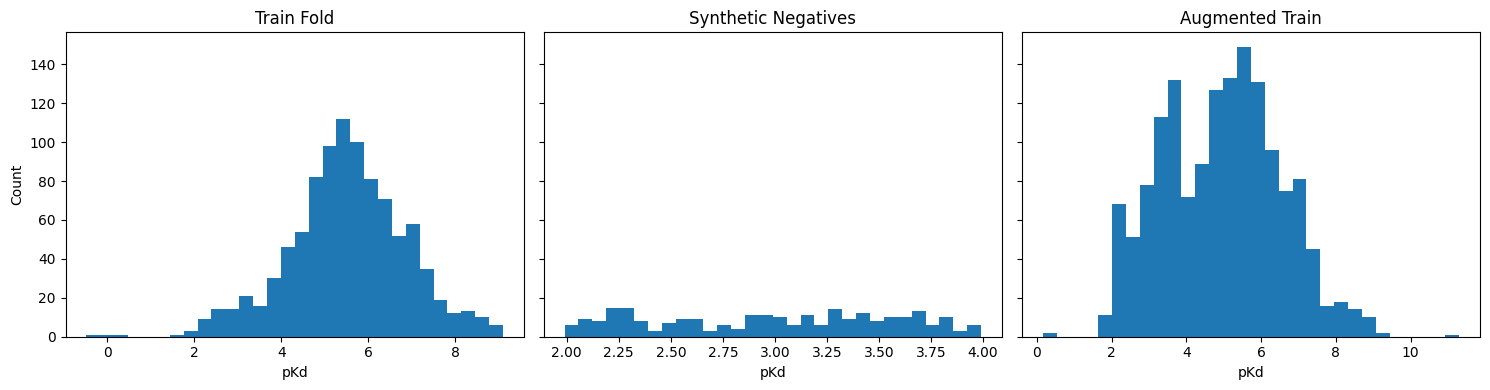

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

# Plot 1 — original training fold
axes[0].hist(train_fold4_df["pKd"], bins=30)
axes[0].set_title("Train Fold")
axes[0].set_xlabel("pKd")
axes[0].set_ylabel("Count")

# Plot 2 — synthetic negatives
axes[1].hist(synthetic_neg_df["pKd"], bins=30)
axes[1].set_title("Synthetic Negatives")
axes[1].set_xlabel("pKd")

# Plot 3 — augmented training set
axes[2].hist(aug_train_df["pKd"], bins=30)
axes[2].set_title("Augmented Train")
axes[2].set_xlabel("pKd")

plt.tight_layout()
plt.show()

### Generate Negative Sampling for 5-Fold Cold Start Setting ###

In [77]:
neg_smoo_folds, _, _ = gen_neg_smoo_cold_fold(cold_folds=cold_folds, smoothing_factor=0.75, negative_factor=1)


===== Fold 1 =====
Train rows:                 1256
Test rows:                  183
Synthetic negatives:        1033
Augmented train rows:       2289
All synthetic pKd < 4.0:    True
No overlap with train:      True
No duplicate synth pairs:   True
Ligand preserved:           True
RNA changed:                True
No overlap with test pairs: True

===== Fold 2 =====
Train rows:                 1196
Test rows:                  243
Synthetic negatives:        976
Augmented train rows:       2172
All synthetic pKd < 4.0:    True
No overlap with train:      True
No duplicate synth pairs:   True
Ligand preserved:           True
RNA changed:                True
No overlap with test pairs: True

===== Fold 3 =====
Train rows:                 1134
Test rows:                  305
Synthetic negatives:        949
Augmented train rows:       2083
All synthetic pKd < 4.0:    True
No overlap with train:      True
No duplicate synth pairs:   True
Ligand preserved:           True
RNA changed:         

In [72]:
neg_smoo_folds['fold5'][0].shape, cold_folds[4][0].shape

((2205, 12), (1210, 8))